# Вклад генераторов кандидатов

Используем сохранённые кандидаты последней модели: 4 000 validation и 10 000 public-test запросов. Полезная находка здесь — размеченный целевой трек для конкретного запроса. Один и тот же трек у разных запросов считается отдельно; другие подходящие треки без метки не оцениваем.

Сравниваем самостоятельный recall, уникальные находки в union top-1000 и вклад при фиксированной адаптивной политике top-150. При исключении источника пересчитываем RRF и заполняем 150 мест из остальных источников; политику заново не подбираем. Это анализ кандидатов, а не важности фичей CatBoost. Метки test используются только для диагностики.

## Данные и настройки

In [1]:
from pathlib import Path
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm

ROOT = next(
    folder
    for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "music4all_crs" / "train_queries.parquet").exists()
)
DATA = ROOT / "music4all_crs"
RETRIEVAL = ROOT / "retrieval_artifacts"
CACHE = RETRIEVAL / "candidate_cache"
MODEL = ROOT / "adaptive150_catboost_artifacts"
OUT = ROOT / "candidate_analysis_artifacts"
OUT.mkdir(exist_ok=True)
NAMES = json.loads((RETRIEVAL / "generators.json").read_text())["generators"]
POLICY = json.loads((MODEL / "candidate_policy.json").read_text())
TRACK_IDS = np.load(RETRIEVAL / "track_ids.npy")
ID_TO_IDX = {x: i for i, x in enumerate(TRACK_IDS)}
TRACKS = pd.read_parquet(
    DATA / "tracks_meta.parquet", columns=["m4a_id", "m4a_artist", "m4a_song"]
)
TRACKS = TRACKS.set_index("m4a_id").loc[TRACK_IDS].reset_index()
normalize = lambda text: " ".join(re.findall(r"\w+", str(text).casefold()))
ARTISTS = TRACKS.m4a_artist.fillna("").map(normalize).to_numpy()
TEXT_SOURCES = {"bm25", "tfidf", "query_tfidf", "metadata_char", "metadata_bm25"}
BASE3 = [NAMES.index(x) for x in ["bm25", "tfidf", "history"]]


## Кандидаты в том же порядке запросов

In [2]:
def load_split(split):
    metrics = pd.read_parquet(MODEL / f"{split}_metrics_per_query.parquet").set_index(
        "query_id"
    )
    prefix = "train" if split == "validation" else "test_public"
    queries = (
        pd.read_parquet(DATA / f"{prefix}_queries.parquet")
        .set_index("query_id")
        .loc[metrics.index]
    )
    labels = (
        pd.read_parquet(DATA / f"{prefix}_qrels.parquet")
        .set_index("query_id")
        .loc[metrics.index]
    )
    sources = {}
    for name in NAMES:
        frame = pd.read_parquet(CACHE / f"{split}_{name}.parquet").set_index("query_id")
        sources[name] = frame.loc[metrics.index, "track_indices"].tolist()
    targets = labels.target_m4a_id.map(ID_TO_IDX).to_numpy()
    assert not pd.isna(targets).any()
    targets = targets.astype(np.int32)
    # Официальные исключения применяются после отбора 150. Проверяем, что
    # целевой трек сам не исключён: тогда проверка присутствия target корректна.
    for pos, row in enumerate(queries.itertuples()):
        if row.query_type == "similar_to":
            label = labels.iloc[pos]
            assert (
                pd.isna(label.exclude_m4a_id)
                or label.exclude_m4a_id != TRACK_IDS[targets[pos]]
            )
            assert (
                pd.isna(label.exclude_artist)
                or not normalize(label.exclude_artist)
                or normalize(label.exclude_artist) != ARTISTS[targets[pos]]
            )
    return queries, labels, targets, sources, metrics


## Recall каждого источника и его уникальные находки

In [3]:
def source_hits(targets, sources):
    hits = np.zeros((len(targets), len(NAMES)), dtype=bool)
    hits150 = np.zeros_like(hits)
    sizes = np.zeros_like(hits, dtype=np.int32)
    for j, name in enumerate(NAMES):
        for i, ids in enumerate(sources[name]):
            assert len(ids) <= 1000
            found = np.flatnonzero(ids == targets[i])
            hits[i, j] = bool(len(found))
            hits150[i, j] = bool(len(found) and found[0] < 150)
            sizes[i, j] = len(ids)
    return hits, hits150, sizes


def cap_target_hit(union, scores, target_position):
    if target_position is None or scores[target_position] <= 0:
        return False
    value = scores[target_position]
    # Эквивалент сортировки (-score, track_idx), но без полной сортировки.
    before = np.count_nonzero(scores > value)
    before += np.count_nonzero((scores == value) & (union < union[target_position]))
    return bool(before < 150)


## Удаляем источник и пересчитываем top-150

In [4]:
def cap_ablation(queries, targets, sources):
    base = np.zeros(len(queries), dtype=bool)
    without = np.zeros((len(queries), len(NAMES)), dtype=bool)
    active = np.zeros_like(without)
    for i, row in enumerate(
        tqdm(queries.itertuples(), total=len(queries), desc="RRF ablations")
    ):
        config = POLICY["by_query_type"].get(row.query_type, POLICY["fallback"])
        names = config["generators"]
        ids_by_source = [np.asarray(sources[name][i], dtype=np.int32) for name in names]
        union = np.unique(np.concatenate(ids_by_source))
        positions = [np.searchsorted(union, ids) for ids in ids_by_source]
        additions = [
            (config["text_weight"] if name in TEXT_SOURCES else 1)
            / (config["rrf_constant"] + np.arange(1, len(ids) + 1))
            for name, ids in zip(names, ids_by_source)
        ]
        target_pos = int(np.searchsorted(union, targets[i]))
        if target_pos == len(union) or union[target_pos] != targets[i]:
            target_pos = None

        def recompute(skip=None):
            values = np.zeros(len(union), dtype=np.float32)
            # Порядок сложения и float32 совпадают с обучающим ноутбуком.
            for name, loc, addition in zip(names, positions, additions):
                if name != skip:
                    values[loc] += addition
            return cap_target_hit(union, values, target_pos)

        base[i] = recompute()
        without[i, :] = base[i]
        for name in names:
            j = NAMES.index(name)
            active[i, j] = True
            without[i, j] = recompute(skip=name)
    return base, without, active


## Таблицы вклада и примеры

In [5]:
def summarize(split, queries, targets, hits, hits150, sizes, base, without, active):
    count = hits.sum(axis=1)
    union_hit = count > 0
    baseline3_hit = hits[:, BASE3].any(axis=1)
    share = hits / np.maximum(count[:, None], 1)
    rows, typed, examples = [], [], []
    for j, name in enumerate(NAMES):
        unique = hits[:, j] & (count == 1)
        lost = base & ~without[:, j]
        recovered = ~base & without[:, j]
        row = dict(
            split=split,
            generator=name,
            n_queries=len(queries),
            hits_top1000=int(hits[:, j].sum()),
            recall_top1000=float(hits[:, j].mean()),
            hits_top150_alone=int(hits150[:, j].sum()),
            recall_top150_alone=float(hits150[:, j].mean()),
            unique_hits_union=int(unique.sum()),
            distinct_found_track_ids=int(len(np.unique(targets[hits[:, j]]))),
            distinct_ids_in_unique_hits=int(len(np.unique(targets[unique]))),
            new_vs_base3=int((hits[:, j] & ~baseline3_hit).sum()),
            shapley_union_hits=float(share[:, j].sum()),
            mean_source_candidates=float(sizes[:, j].mean()),
            active_queries=int(active[:, j].sum()),
            target_in_source_and_cap150=int((hits[:, j] & active[:, j] & base).sum()),
            lost_without_source=int(lost.sum()),
            recovered_without_source=int(recovered.sum()),
            net_hits_cap150=int(lost.sum() - recovered.sum()),
            delta_recall_cap150=float(base.mean() - without[:, j].mean()),
            recall_without_source=float(without[:, j].mean()),
        )
        rows.append(row)
        for query_type in queries.query_type.unique():
            mask = queries.query_type.to_numpy() == query_type
            typed.append(
                dict(
                    split=split,
                    query_type=query_type,
                    generator=name,
                    n_queries=int(mask.sum()),
                    recall_top1000=float(hits[mask, j].mean()),
                    recall_top150_alone=float(hits150[mask, j].mean()),
                    baseline_cap_recall=float(base[mask].mean()),
                    unique_hits_union=int(unique[mask].sum()),
                    lost_without_source=int(lost[mask].sum()),
                    recovered_without_source=int(recovered[mask].sum()),
                    delta_recall_cap150=float(
                        base[mask].mean() - without[mask, j].mean()
                    ),
                )
            )
        for kind, mask in [
            ("unique_top1000", unique),
            ("lost_cap150", lost),
            ("recovered_cap150", recovered),
        ]:
            for pos in np.flatnonzero(mask)[:5]:
                examples.append(
                    dict(
                        split=split,
                        generator=name,
                        kind=kind,
                        query_id=queries.index[pos],
                        query_type=queries.iloc[pos].query_type,
                        query=queries.iloc[pos]["query"],
                    )
                )
    totals = dict(
        split=split,
        n_queries=len(queries),
        base3_hits=int(baseline3_hit.sum()),
        union_hits=int(union_hit.sum()),
        recall_base3=float(baseline3_hit.mean()),
        recall_all11=float(union_hit.mean()),
        cap150_hits=int(base.sum()),
        recall_cap150=float(base.mean()),
    )
    assert np.isclose(sum(r["shapley_union_hits"] for r in rows), union_hit.sum())
    return pd.DataFrame(rows), pd.DataFrame(typed), pd.DataFrame(examples), totals


summaries, by_types, examples, totals = [], [], [], []
for split in ["validation", "test"]:
    queries, labels, targets, sources, metrics = load_split(split)
    hits, hits150, sizes = source_hits(targets, sources)
    base, without, active = cap_ablation(queries, targets, sources)
    assert np.array_equal(
        hits.any(axis=1), metrics.recall_uncapped.to_numpy(dtype=bool)
    )
    assert np.array_equal(base, metrics.recall_union.to_numpy(dtype=bool))
    a, b, c, total = summarize(
        split, queries, targets, hits, hits150, sizes, base, without, active
    )
    examples_with_tracks = c.merge(
        labels[["target_m4a_id"]], left_on="query_id", right_index=True
    )
    examples_with_tracks = examples_with_tracks.merge(
        TRACKS[["m4a_id", "m4a_song", "m4a_artist"]],
        left_on="target_m4a_id",
        right_on="m4a_id",
    )
    summaries.append(a)
    by_types.append(b)
    examples.append(examples_with_tracks)
    totals.append(total)
    display(pd.DataFrame([total]))
summary = pd.concat(summaries, ignore_index=True)
by_type = pd.concat(by_types, ignore_index=True)
examples = pd.concat(examples, ignore_index=True)
overall = pd.DataFrame(totals)
for name, table in [
    ("summary", summary),
    ("by_query_type", by_type),
    ("examples", examples),
    ("overall", overall),
]:
    table.to_csv(OUT / f"{name}.csv", index=False)
display(
    summary[summary.split == "test"].sort_values("net_hits_cap150", ascending=False)
)


        split  n_queries  base3_hits  ...  recall_all11  cap150_hits  recall_cap150
0  validation       4000        3652  ...        0.9515         2834         0.7085

[1 rows x 8 columns]
  split  n_queries  base3_hits  ...  recall_all11  cap150_hits  recall_cap150
0  test      10000        9071  ...        0.9489         6833         0.6833

[1 rows x 8 columns]
   split          generator  ...  delta_recall_cap150  recall_without_source
11  test               bm25  ...               0.1080                 0.5753
16  test      metadata_char  ...               0.0754                 0.6079
13  test            history  ...               0.0514                 0.6319
21  test     history_recent  ...               0.0139                 0.6694
14  test        query_tfidf  ...               0.0079                 0.6754
19  test  history_frequency  ...               0.0048                 0.6785
12  test              tfidf  ...               0.0007                 0.6826
15  test   favor

## Вклад на public test

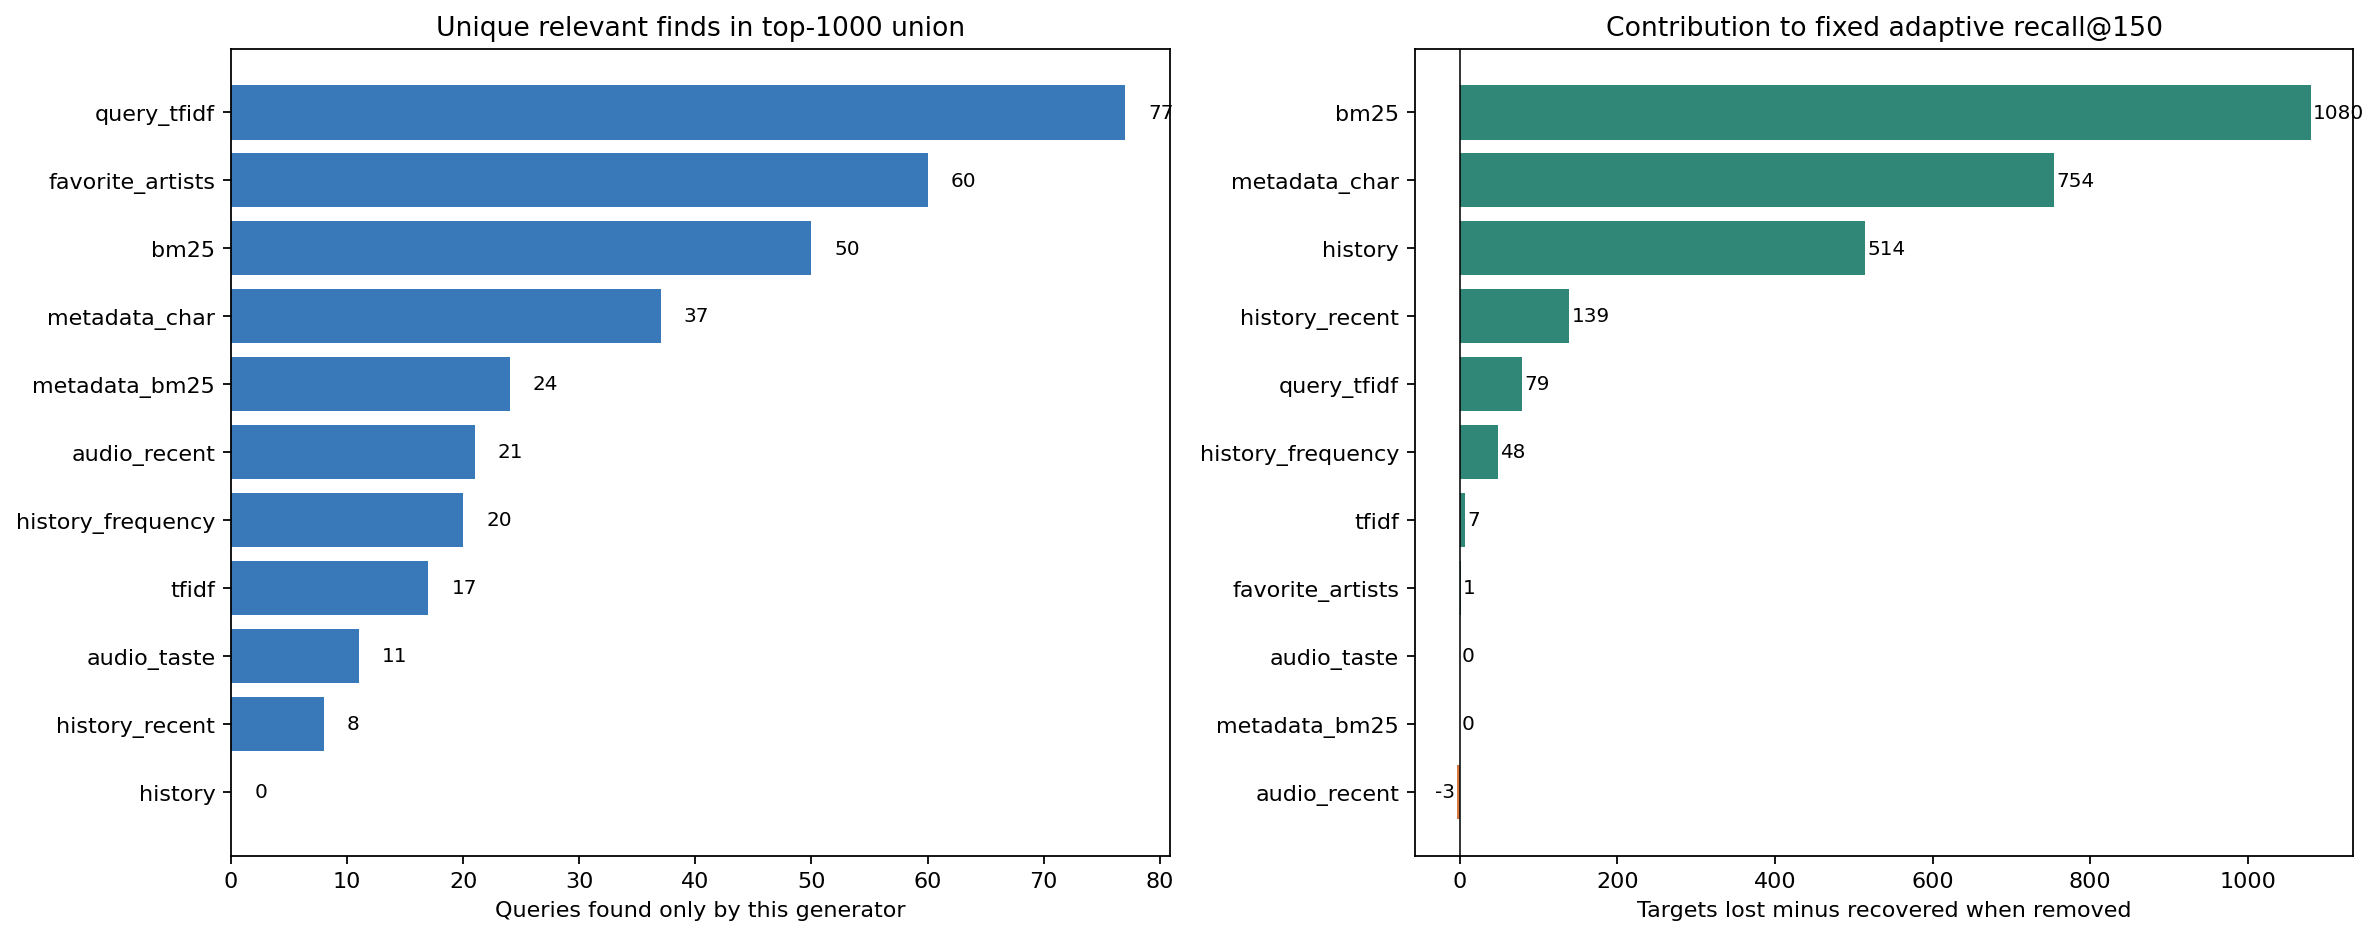

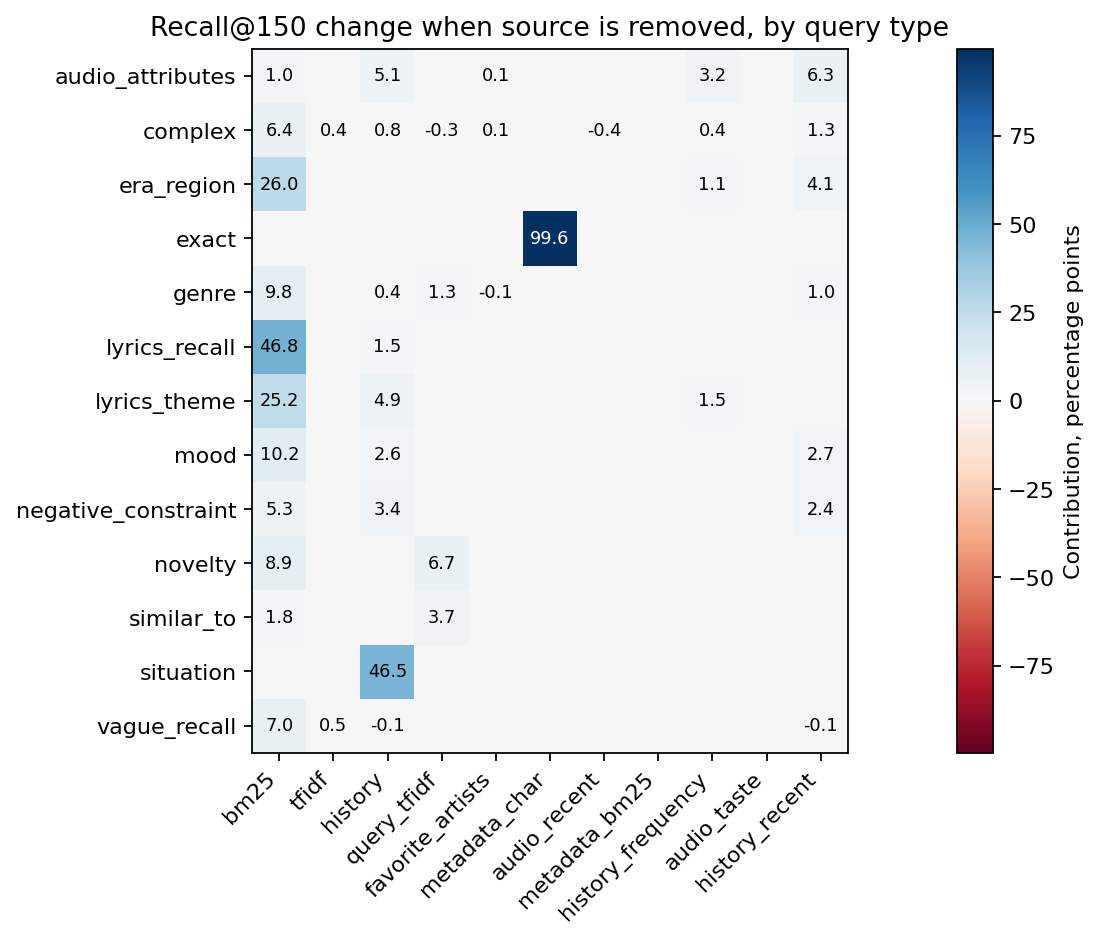

In [6]:
test = summary[summary.split == "test"].set_index("generator")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
raw = test.sort_values("unique_hits_union")
axes[0].barh(raw.index, raw.unique_hits_union, color="#3979b9")
axes[0].set_title("Unique relevant finds in top-1000 union")
axes[0].set_xlabel("Queries found only by this generator")
for i, value in enumerate(raw.unique_hits_union):
    axes[0].text(value + 2, i, str(value), va="center", fontsize=9)
cap = test.sort_values("net_hits_cap150")
axes[1].barh(
    cap.index,
    cap.net_hits_cap150,
    color=["#d87941" if x < 0 else "#308777" for x in cap.net_hits_cap150],
)
axes[1].axvline(0, color="black", linewidth=0.7)
axes[1].set_title("Contribution to fixed adaptive recall@150")
axes[1].set_xlabel("Targets lost minus recovered when removed")
for i, value in enumerate(cap.net_hits_cap150):
    axes[1].text(
        value + (3 if value >= 0 else -3),
        i,
        str(value),
        ha="left" if value >= 0 else "right",
        va="center",
        fontsize=9,
    )
fig.tight_layout()
fig.savefig(OUT / "generator_contribution.png", dpi=160, bbox_inches="tight")
plt.show()
heat = (
    by_type[by_type.split == "test"]
    .pivot(index="query_type", columns="generator", values="delta_recall_cap150")
    .reindex(columns=NAMES)
)
fig, ax = plt.subplots(figsize=(14, 6))
limit = max(float(np.abs(heat.to_numpy()).max()), 0.01)
im = ax.imshow(heat.to_numpy() * 100, cmap="RdBu", vmin=-limit * 100, vmax=limit * 100)
ax.set_xticks(np.arange(len(NAMES)), NAMES, rotation=45, ha="right")
ax.set_yticks(np.arange(len(heat)), heat.index)
ax.set_title("Recall@150 change when source is removed, by query type")
for i in range(len(heat)):
    for j in range(len(NAMES)):
        value = heat.iloc[i, j] * 100
        if abs(value) >= 0.05:
            ax.text(
                j,
                i,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if abs(value) > limit * 60 else "black",
            )
fig.colorbar(im, ax=ax, label="Contribution, percentage points")
fig.tight_layout()
fig.savefig(OUT / "contribution_by_type.png", dpi=160, bbox_inches="tight")
plt.show()


## Как читать результаты

`unique_hits_union` — находки, отсутствующие у всех остальных 10 источников. `new_vs_base3` — дополнительные находки относительно union BM25 + TF-IDF + history, при top-1000 каждого источника. Эти числа не отражают порядок RRF. `shapley_union_hits` делит каждую найденную цель поровну между нашедшими её источниками; сумма равна числу целей в полном union.

`lost_without_source` и `recovered_without_source` относятся к адаптивному top-150. Положительный `net_hits_cap150` означает полезный вклад: без источника найдено меньше целей. Отрицательный означает, что удаление источника улучшило recall на этой выборке, освободив места для других кандидатов. Вклады top-150 не складываются. Источник, не используемый политикой на конкретном типе запроса, имеет нулевой вклад в отбор, но может оставаться полезным как источник фичей CatBoost.

Выборки не охватывают полный public test, поэтому числа нельзя автоматически переносить на все 273 137 запросов. Удаление генераторов или подбор новой политики по public-test меткам здесь не производится.